# Predecir volatilidad alta a 5 días: una evaluación honesta

## 1. El problema y por qué volatilidad

Predecir **hacia dónde** se moverá el precio de una acción es casi un volado: los retornos diarios casi no tienen autocorrelación. La **volatilidad**, en cambio, **se agrupa en el tiempo** (los días turbulentos vienen en racimo). Eso la hace la parte más predecible del mercado y útil en la práctica (dimensionar posiciones, cubrir riesgo).

**Pregunta:** dado lo que sabemos al cierre del día *t*, ¿la volatilidad de los próximos 5 días hábiles de este ticker será **alta**?

Primero, verifiquemos con datos que la premisa se sostiene.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

from src import data as D
from src import features as F
from src.train import load_dataset, temporal_split, DECISION_THRESHOLD

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent
prices = D.load_prices()
rets = prices.pct_change()

ac_abs = rets.abs().apply(lambda s: s.autocorr(1)).mean()
ac_ret = rets.apply(lambda s: s.autocorr(1)).mean()
v5 = rets.rolling(5).std() * np.sqrt(252)
corr_vol = pd.concat([v5.stack(), v5.shift(-5).stack()], axis=1).corr().iloc[0, 1]
print(f"Autocorrelación lag-1 del retorno:          {ac_ret:+.3f}  (casi nula, y ligeramente negativa)")
print(f"Autocorrelación lag-1 del retorno absoluto: {ac_abs:+.3f}  (la volatilidad se agrupa)")
print(f"Correlación entre vol 5d actual y vol 5d siguiente: {corr_vol:.2f}")

Autocorrelación lag-1 del retorno:          -0.058  (casi nula, y ligeramente negativa)
Autocorrelación lag-1 del retorno absoluto: +0.251  (la volatilidad se agrupa)
Correlación entre vol 5d actual y vol 5d siguiente: 0.51


Los retornos casi no se parecen a los del día anterior (≈ -0,06), pero la magnitud de los movimientos sí (≈ +0,25), y la volatilidad de la semana pasada se correlaciona ~0,5 con la de la semana siguiente. Hay señal… pero moderada: no esperemos milagros.

## 2. Definición exacta del target

Para cada ticker y fecha *t*:

- `vol_5d_trailing(t)`: desviación estándar de los retornos de *t-4..t*, anualizada (× √252).
- `umbral(t)`: **mediana de los últimos 252 días** de `vol_5d_trailing` del mismo ticker (solo datos ≤ *t*).
- `vol_fwd_5d(t)`: desviación estándar de los retornos de *t+1..t+5*, anualizada.
- **`target(t) = 1` si `vol_fwd_5d(t) > umbral(t)`**, si no 0.

Un umbral **relativo al ticker y a su propio pasado** permite comparar una utility con NVIDIA y no usa información futura. Por construcción ~50 % de los días son positivos, pero la tasa varía por régimen:

In [2]:
X, y = load_dataset()
dates = X.index.get_level_values("Date")
print(f"Dataset: {X.shape[0]:,} filas (ticker-día), {X.shape[1]} features, {dates.min():%Y-%m-%d} a {dates.max():%Y-%m-%d}")
rate = y.groupby(dates.year).mean()
fig, ax = plt.subplots(figsize=(9, 3.5))
rate.plot.bar(ax=ax, color=["firebrick" if r > .55 else "steelblue" for r in rate])
ax.axhline(.5, color="k", ls="--"); ax.set_ylabel("% de días con vol alta"); ax.set_title("Tasa del target por año")
plt.show()

Dataset: 40,064 filas (ticker-día), 24 features, 2016-01-08 a 2025-12-22


2018, 2020 y 2022 (años de estrés) tienen mucho más del 50 % de días de "vol alta", y 2023 mucho menos. **Esto es importante**: el modelo tendrá que funcionar en un régimen distinto al de entrenamiento.

## 3. Features (24, todas con información ≤ *t*)

| Grupo | Features |
|---|---|
| Volatilidad propia | `vol_5`, `vol_21`, `vol_63`, `vol_ratio_5_63`, `vol_ratio_21_63`, `vol5_vs_med252` (vol actual / umbral) |
| Precio | `ret_1`, `ret_5`, `ret_21`, `abs_ret_1`, `dd_63` (drawdown desde máx. de 63d) |
| Mercado | `spy_vol_5`, `spy_vol_21`, `vix`, `vix_chg_5`, `vix_vs_ma63` |
| Actividad | `volume_ratio_5_63` |
| Calendario / sector | `dow`, one-hot de sector (6) |

La garantía **anti-leakage** está cubierta por tests (`tests/test_features.py`): alterar precios, VIX o volumen posteriores a *t* no cambia ninguna feature en *t*.

## 4. Validación temporal

Nada de mezclar fechas al azar. Cortamos en el tiempo:

- **Train 2015-2021** → tuning con `TimeSeriesSplit` por fechas (gap de 5 días).
- **Validación 2022** → elegir el modelo ganador.
- **Test 2023-2025** → se usa **una sola vez**, al final.
- Se eliminan los últimos 5 días de train y de validación (*purge*), porque su target usa retornos del tramo siguiente.
- Para evaluar en test, cada modelo se reentrena con train + validación.

In [3]:
sp = temporal_split(X)
for k in ("train", "val", "test"):
    d = dates[sp[k]]
    print(f"{k:>5}: {sp[k].sum():>6,} filas  {d.min():%Y-%m-%d} → {d.max():%Y-%m-%d}   tasa positiva = {y[sp[k]].mean():.2f}")

train: 24,032 filas  2016-01-08 → 2021-12-23   tasa positiva = 0.48
  val:  3,936 filas  2022-01-03 → 2022-12-22   tasa positiva = 0.65
 test: 11,936 filas  2023-01-03 → 2025-12-22   tasa positiva = 0.45


## 5. Modelos vs baseline

Tres baselines, de menos a más exigente:

- **Persistencia** (sin entrenar): "mañana será como hoy" → vol alta si `vol_5 > umbral`.
- **Logística de 1 feature** (`vol5_vs_med252`), entrenada igual que las demás. Es una transformación monótona de la persistencia: mismo ranking, mismo ROC-AUC; solo cambia el umbral y la calibración.
- **HAR-RV** (Corsi, 2009): regresión lineal de la vol futura sobre la vol realizada **diaria** (|retorno|), **semanal** (5d) y **mensual** (22d), con OLS agrupado entre tickers. Su predicción se divide por el umbral del ticker y se usa como score (> 1 → vol alta). Es el estándar de la literatura para pronosticar volatilidad con solo precios.

Y los modelos completos (24 features):

- **Regresión logística** (con escalado), **Random Forest** y **XGBoost** con búsqueda aleatoria ligera de hiperparámetros.
- La selección del ganador se hace **solo entre los modelos completos y solo por ROC-AUC en validación** (2022); el test nunca interviene en la elección. Los baselines no compiten: el artefacto que consumirá la API usa las 24 features.
- Umbral de decisión fijo en 0,5 (el target es ~50 % positivo; optimizarlo sobre 2022, un año con 65 % de positivos, lo sesgaría).

In [4]:
M = json.loads((ROOT / "reports" / "metrics.json").read_text(encoding="utf-8"))
cols = ["roc_auc", "pr_auc", "f1", "precision", "recall", "brier"]
names = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "f1": "F1", "precision": "Precisión", "recall": "Recall", "brier": "Brier"}
fmt = lambda d: pd.DataFrame(d).T[cols].astype(float).rename(columns=names).round(3)
print("VALIDACIÓN (2022)"); display(fmt(M["validation"]))
print("TEST (2023-2025)"); display(fmt(M["test"]))
print("Mejor modelo elegido por validación:", M["best_model"])

VALIDACIÓN (2022)


,ROC-AUC,PR-AUC,F1,Precisión,Recall,Brier
Persistencia,0.584,0.723,0.678,0.677,0.679,NaN
Logística 1 feature,0.584,0.723,0.604,0.707,0.527,0.244
HAR-RV,0.627,0.753,0.737,0.688,0.794,NaN
Regresión logística,0.713,0.814,0.729,0.758,0.701,0.207
Random Forest,0.644,0.766,0.756,0.679,0.852,0.217
XGBoost,0.666,0.781,0.734,0.708,0.762,0.216


TEST (2023-2025)


,ROC-AUC,PR-AUC,F1,Precisión,Recall,Brier
Persistencia,0.588,0.546,0.517,0.515,0.518,NaN
Logística 1 feature,0.588,0.546,0.464,0.537,0.408,0.243
HAR-RV,0.627,0.577,0.592,0.518,0.690,NaN
Regresión logística,0.646,0.598,0.517,0.597,0.455,0.233
Random Forest,0.614,0.583,0.459,0.578,0.380,0.236
XGBoost,0.639,0.598,0.475,0.600,0.393,0.235


Mejor modelo elegido por validación: Regresión logística


### Lectura honesta

- **Sí hay señal, pero modesta.** En test el mejor modelo (regresión logística) logra **ROC-AUC 0,646 vs 0,588 de la persistencia** (+0,06) y PR-AUC 0,598 vs 0,546. XGBoost queda casi igual (0,639) y Random Forest peor (0,614). Un AUC de 0,5 sería azar; esto está lejos de ser una bola de cristal.
- **El baseline HAR-RV es mucho más duro que la persistencia: ROC-AUC 0,627.** La logística completa solo lo supera por +0,019 (ver sección siguiente).
- **Los modelos complejos no ganan**: la logística, el modelo más simple, fue el mejor en validación (0,713) y en test. Con 24 features muy correlacionadas y un régimen cambiante, la flexibilidad extra no ayuda.
- **El F1 con umbral 0,5 es casi igual al baseline** (0,517 vs 0,517): los modelos son más precisos (≈ 0,60 vs 0,52) pero con menos recall (≈ 0,45). La mejora está en el *ranking* de probabilidades (AUC), no tanto en la etiqueta dura.
- **Calibración:** el Brier de ~0,233-0,236 es apenas mejor que predecir siempre la tasa base (~0,25). Las probabilidades deben leerse como un puntaje de riesgo relativo, no como probabilidades exactas.
- Bajó el rendimiento de validación (0,713) a test (0,646): el régimen de 2022 (alta volatilidad persistente) era más "fácil" que 2023-2025.

Como contraste: usando las mismas features para predecir la **dirección** del retorno a 5 días, el AUC en test es solo ~0,53: casi azar. La volatilidad sí es mucho más predecible.

In [5]:
# Contraste: ¿y la dirección del precio con las mismas features?
fwd = prices.pct_change(5).shift(-5).stack(future_stack=True)
fwd.index.names = ["Date", "Ticker"]
fwd = fwd.reindex(X.index)
ok = fwd.notna().to_numpy()
yd = (fwd > 0).astype(int)
mdl = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(
    X[sp["trainval"] & ok], yd[sp["trainval"] & ok])
auc_dir = roc_auc_score(yd[sp["test"] & ok], mdl.predict_proba(X[sp["test"] & ok])[:, 1])
print(f"AUC en test prediciendo DIRECCIÓN a 5 días: {auc_dir:.3f}   vs   volatilidad: {M['test'][M['best_model']]['roc_auc']:.3f}")

AUC en test prediciendo DIRECCIÓN a 5 días: 0.527   vs   volatilidad: 0.646

### ¿Cuánto de la mejora viene de las features adicionales?

Descomponemos la ganancia de ROC-AUC en test respecto a la persistencia. Los intervalos salen de un bootstrap por bloques mensuales (para respetar la autocorrelación temporal).

In [6]:
FC = M["feature_contribution"]
auc = FC["auc_test"]
steps = pd.DataFrame({
    "ROC-AUC test": auc,
    "Δ vs persistencia": {k: v - auc["Persistencia"] for k, v in auc.items()},
}).round(3)
display(steps)

boot = pd.DataFrame(FC["bootstrap_auc_diff_by_month_blocks"]).T
boot["ci95"] = boot["ci95"].apply(lambda c: f"[{c[0]:+.3f}, {c[1]:+.3f}]")
boot = boot.rename(columns={"mean": "Δ AUC", "ci95": "IC 95 %", "prob_positive": "P(Δ>0)"})
boot["Δ AUC"] = boot["Δ AUC"].round(3); boot["P(Δ>0)"] = boot["P(Δ>0)"].round(2)
display(boot)
print("HAR-RV coeficientes:", {k: round(v, 3) for k, v in M["har_rv_coefficients"].items()})
sh = FC["share_of_gain_from_extra_features_vs_har"]
print(f"Fracción de la ganancia total (vs persistencia) que NO explica la estructura HAR: {sh:.0%}")

,ROC-AUC test,Δ vs persistencia
Persistencia,0.588,0.000
Logística 1 feature,0.588,0.000
HAR-RV,0.627,0.039
Regresión logística,0.646,0.057
Random Forest,0.614,0.026
XGBoost,0.639,0.051


,Δ AUC,IC 95 %,P(Δ>0)
Regresión logística - Logística 1 feature,0.057,"[+0.033, +0.081]",1.0
Regresión logística - HAR-RV,0.019,"[-0.001, +0.036]",0.96
Regresión logística - Persistencia,0.057,"[+0.033, +0.081]",1.0
HAR-RV - Persistencia,0.038,"[+0.025, +0.052]",1.0
Logística 1 feature - Persistencia,0.0,"[+0.000, +0.000]",0.0


HAR-RV coeficientes: {'har_d': 0.088, 'har_w': 0.259, 'har_m': 0.386, 'intercept': 0.058}
Fracción de la ganancia total (vs persistencia) que NO explica la estructura HAR: 32%


**Respuesta honesta:** la mayor parte de la mejora **no** viene de las features adicionales, sino de mirar la volatilidad en **varias escalas de tiempo**.

- Pasar de la persistencia (0,588) a HAR-RV (0,627) da **+0,038** (IC 95 % [+0,025, +0,052]): solo con la vol diaria, semanal y mensual ya se captura ~2/3 de la ganancia total.
- Pasar de HAR-RV a la logística con 24 features da **+0,019**, con un IC 95 % que **roza el cero** ([-0,001, +0,036]) y P(Δ>0) ≈ 0,96. Es una mejora pequeña y estadísticamente marginal: el VIX, el volumen, el drawdown y el sector aportan algo, pero poco.
- La logística de una sola feature **no mejora** la persistencia en AUC (es una transformación monótona): confirma que el salto de 0,588 a 0,627 viene de la estructura multi-horizonte, no de "entrenar".
- En F1 con umbral 1 HAR-RV (0,592) incluso supera a la logística completa a umbral 0,5 (0,517), porque su umbral implícito favorece el recall; los puntos de operación no son directamente comparables.

Conclusión práctica: para **este** problema, un modelo HAR simple es un competidor serio; el valor incremental de las 24 features es real pero reducido.

### Curva de calibración y matrices de confusión (test)

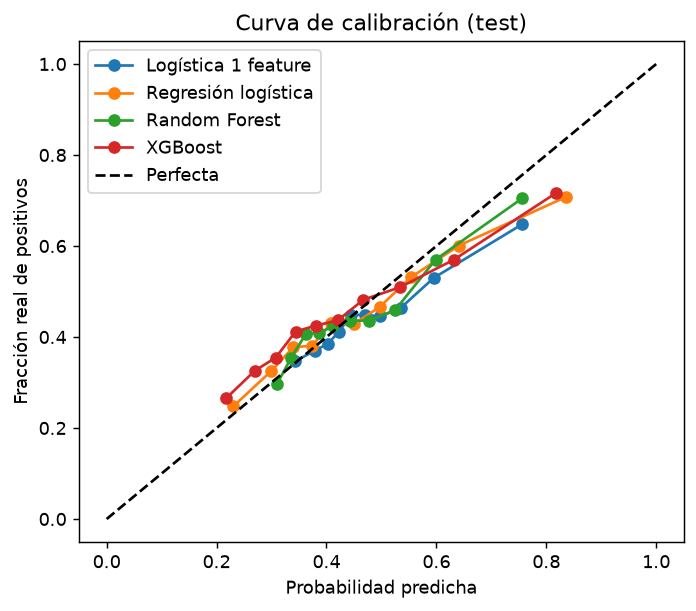

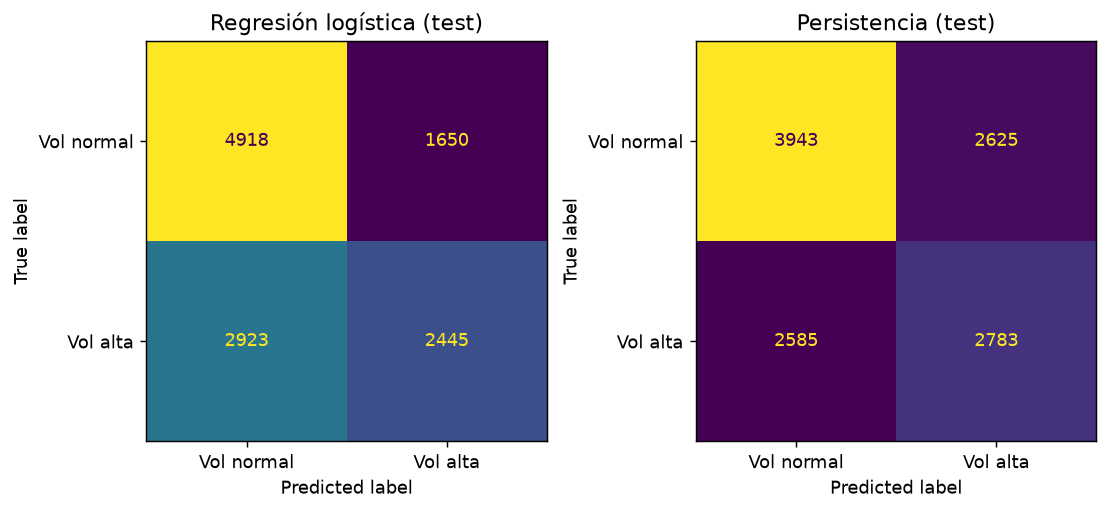

In [7]:
display(Image(ROOT / "reports" / "figures" / "calibration.png", width=480))
display(Image(ROOT / "reports" / "figures" / "confusion_matrix.png", width=700))

### Por sector y por año (test)

ROC-AUC en test para todos los modelos y baselines:

In [8]:
order = list(M["test"])
sec_df = pd.DataFrame({s: {m: v[m]["roc_auc"] for m in order} for s, v in M["test_by_sector"].items()}).round(3)
yr_df = pd.DataFrame({a: {m: v[m]["roc_auc"] for m in order} for a, v in M["test_by_year"].items()}).round(3)
yr_df.loc["(tasa positiva)"] = [M["test_by_year"][a][order[0]]["base_rate"] for a in yr_df.columns]
print("Por sector"); display(sec_df)
print("Por año"); display(yr_df.round(3))

Por sector


,Bancos,Consumo,Energía,Índice,Salud,Tecnología
Persistencia,0.549,0.603,0.522,0.671,0.584,0.608
Logística 1 feature,0.549,0.603,0.522,0.671,0.584,0.608
HAR-RV,0.574,0.650,0.581,0.736,0.595,0.649
Regresión logística,0.640,0.657,0.603,0.774,0.575,0.659
Random Forest,0.614,0.600,0.530,0.730,0.558,0.643
XGBoost,0.642,0.620,0.578,0.754,0.579,0.660


Por año


,2023,2024,2025
Persistencia,0.548,0.543,0.613
Logística 1 feature,0.548,0.543,0.613
HAR-RV,0.573,0.552,0.640
Regresión logística,0.604,0.576,0.677
Random Forest,0.576,0.566,0.664
XGBoost,0.598,0.589,0.671
(tasa positiva),0.317,0.511,0.522


- **Frente a la persistencia**, el modelo completo mejora en 5 de 6 sectores (sobre todo Índice/SPY, 0,77 vs 0,67, y Bancos, 0,64 vs 0,55).
- **Frente a HAR-RV la ventaja se reduce**: +0,066 en Bancos, +0,038 en SPY, +0,022 en Energía, y casi nula en Consumo (0,657 vs 0,650) y Tecnología (0,659 vs 0,649).
- **Salud es la excepción**: 0,575 del modelo, por debajo de la persistencia (0,584) y de HAR-RV (0,595). Probablemente su volatilidad depende más de eventos idiosincráticos (resultados, regulación) que del mercado.
- **Por año**, el modelo supera a HAR-RV en 2023, 2024 y 2025 (0,604/0,576/0,677 vs 0,573/0,552/0,640), así que la pequeña ventaja es consistente en el tiempo, no de un solo año.

## 6. Explicabilidad con SHAP

Valores SHAP del modelo final sobre una muestra de test.

Top-5 por |SHAP| medio: ['vol5_vs_med252', 'vol_5', 'vol_ratio_5_63', 'vix_vs_ma63', 'dd_63']


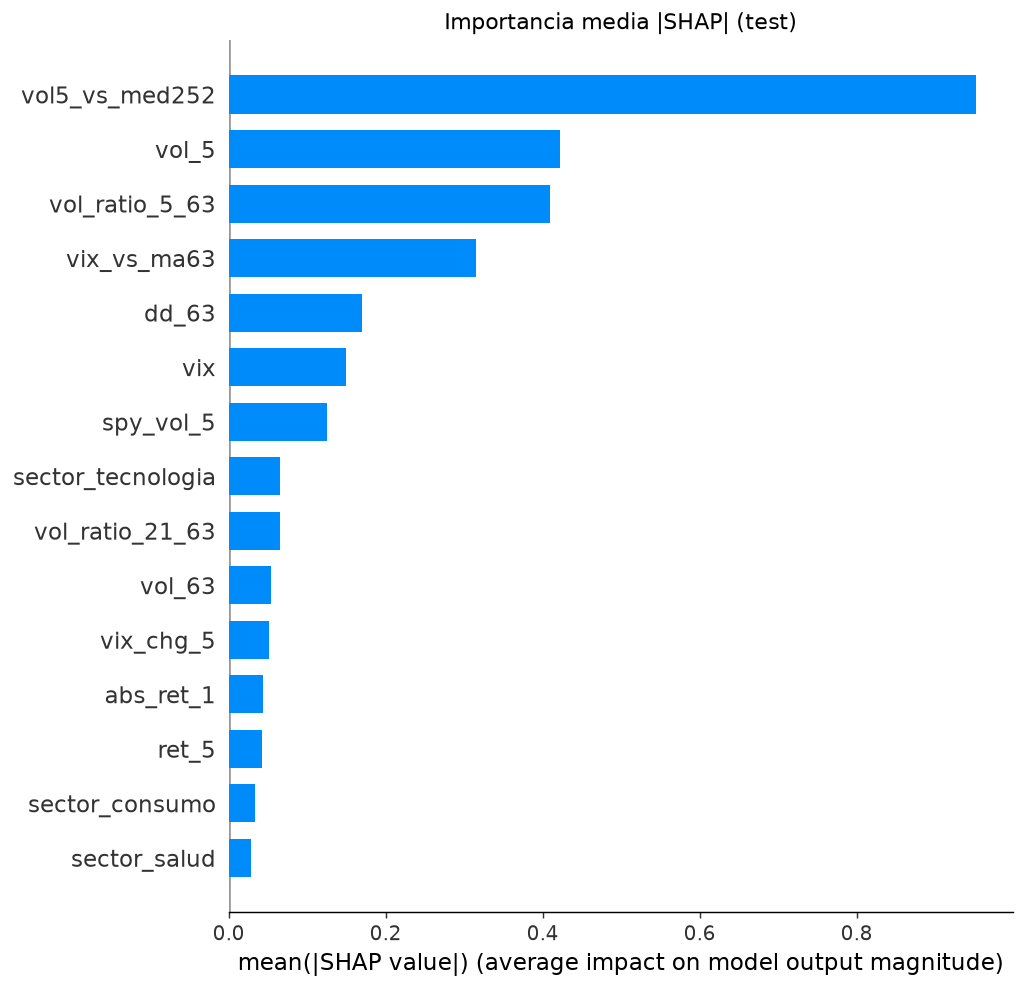

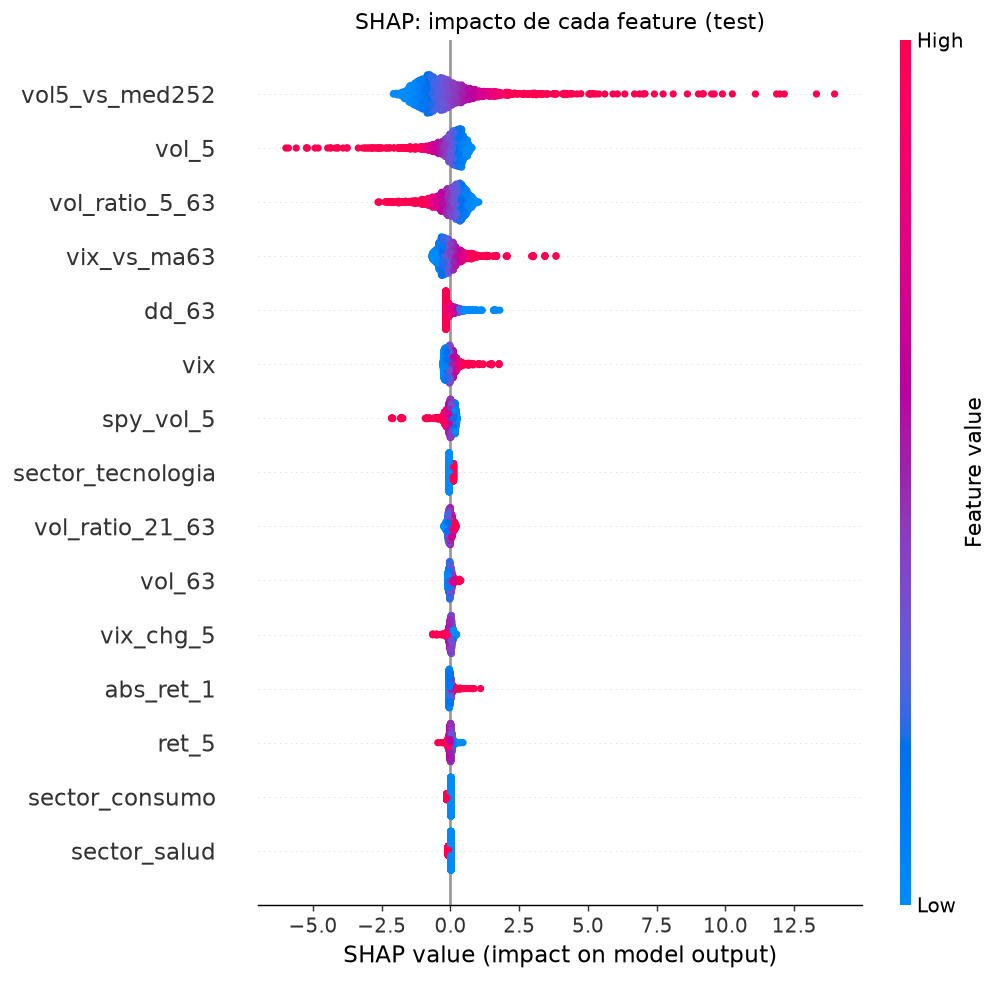

In [9]:
imp = json.loads((ROOT / "reports" / "shap_importance.json").read_text(encoding="utf-8"))
print("Top-5 por |SHAP| medio:", list(imp)[:5])
display(Image(ROOT / "reports" / "figures" / "shap_bar.png", width=560))
display(Image(ROOT / "reports" / "figures" / "shap_summary.png", width=620))

- Las **5 features más importantes** son `vol5_vs_med252`, `vol_5`, `vol_ratio_5_63`, `vix_vs_ma63` y `dd_63`: la propia volatilidad reciente (en relativo a su nivel normal), el VIX respecto a su media y qué tan lejos está el precio de su máximo.
- La dirección de los efectos es financieramente coherente: vol reciente alta relativa a lo normal → más probabilidad de vol alta; VIX por encima de su media → más; precio muy por debajo de su máximo (drawdown profundo) → más.
- Sector, día de la semana y retornos tienen impacto mínimo.

### Dos casos concretos

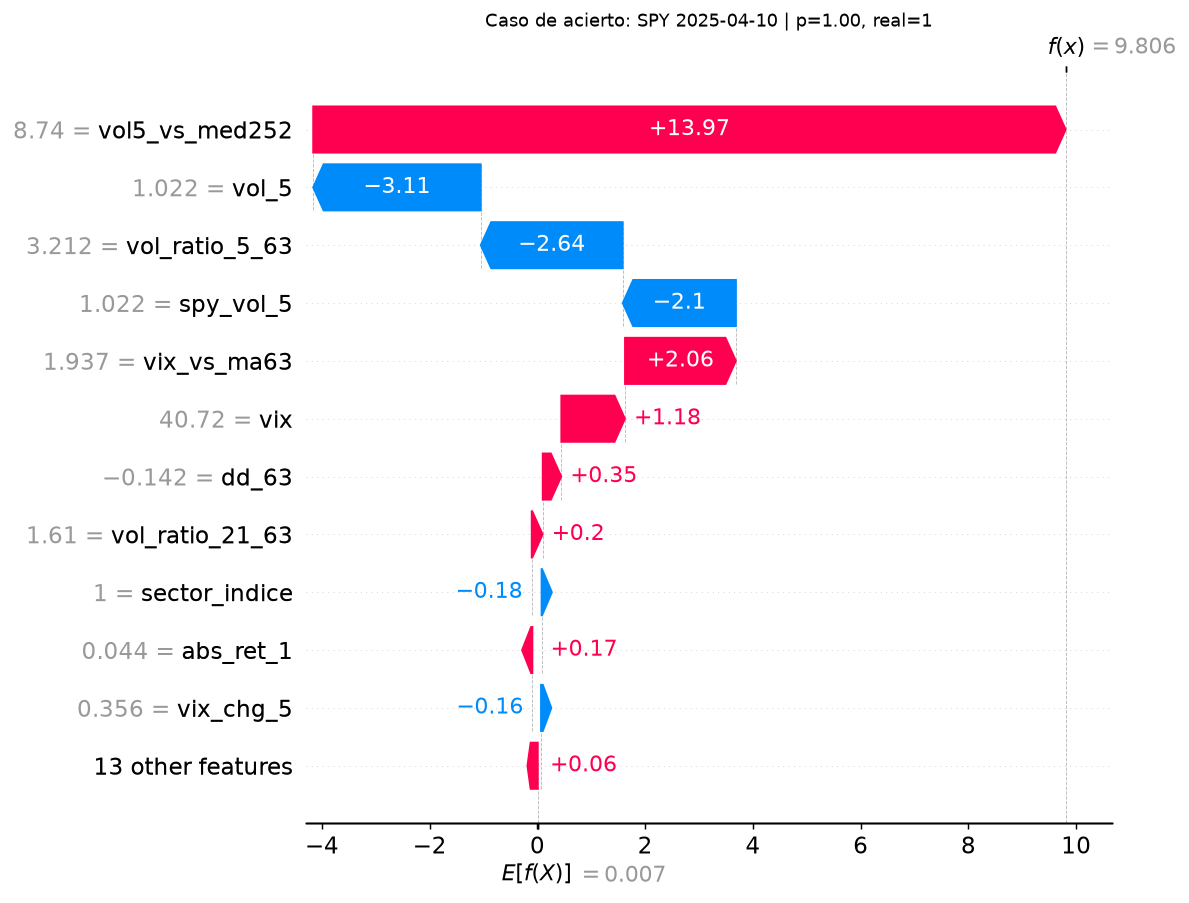

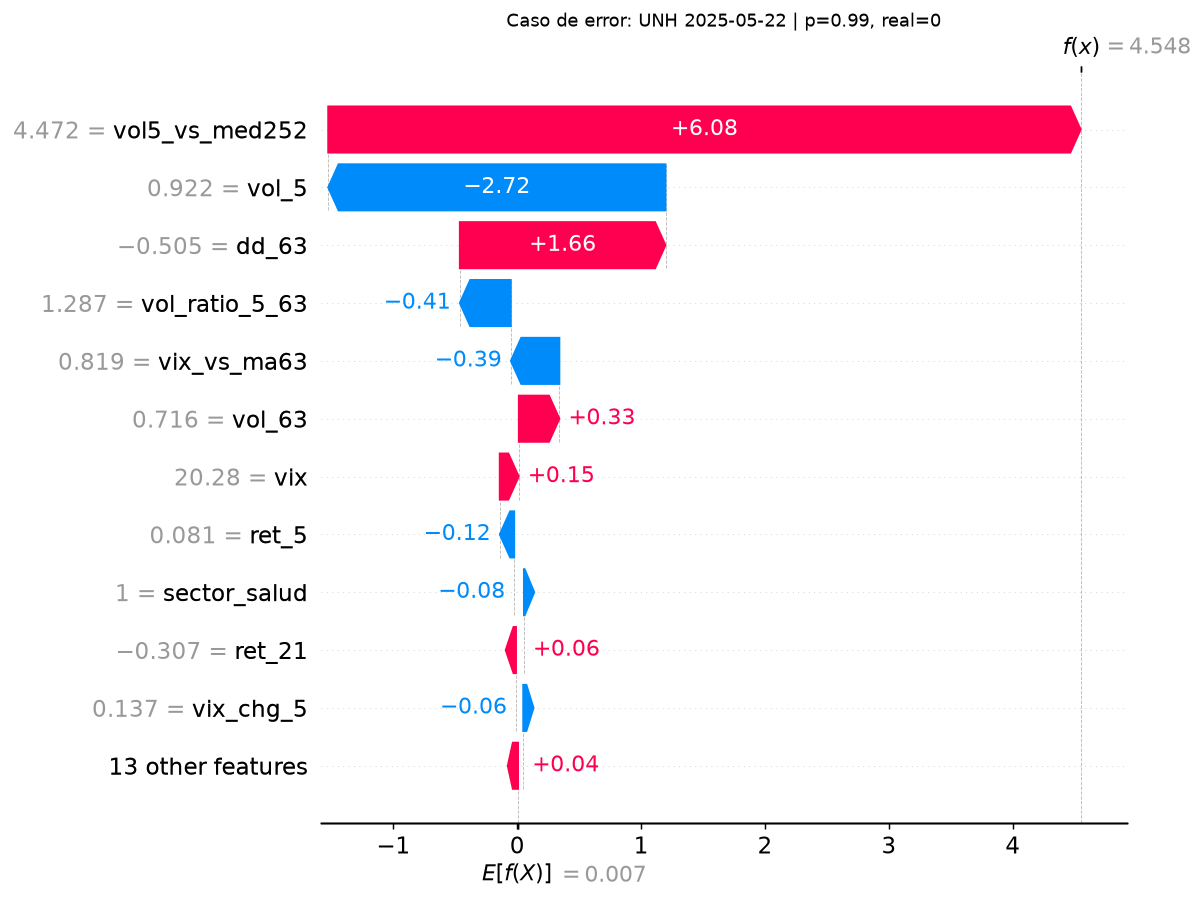

In [10]:
display(Image(ROOT / "reports" / "figures" / "shap_waterfall_acierto.png", width=640))
display(Image(ROOT / "reports" / "figures" / "shap_waterfall_error.png", width=640))

El caso de **error** muestra una debilidad real: con `vol5_vs_med252` en un valor extremo (≈ 4,5 veces lo normal) el modelo lineal extrapola y dispara una probabilidad de ~0,99, sin considerar que `vol_5` y `vol_ratio_5_63` ya estaban moderados. Es plausible que ante un pico aislado de un solo ticker (p. ej. un gap por resultados) el modelo sobrerreaccione; es una hipótesis a investigar, no algo que hayamos medido.

## 7. Limitaciones y próximos pasos

**Limitaciones**
- Mejora real pero modesta (+0,06 AUC sobre persistencia) y **solo +0,019 sobre un HAR-RV simple** (IC 95 % que roza el cero): buena parte del valor viene de la estructura multi-horizonte de la volatilidad, no de las features extra. Las probabilidades están poco calibradas y el F1 con umbral 0,5 no supera al baseline.
- Cambio de régimen: validación (2022) y test (2023-25) tienen tasas de positivos distintas; un solo corte temporal es una estimación ruidosa.
- Universo de 16 tickers grandes y líquidos elegidos hoy (sesgo de supervivencia), un solo horizonte (5 días), sin costos ni estrategia de trading.
- El modelo lineal extrapola mal ante valores extremos; los modelos de árboles no mejoraron en test.
- No usa eventos (earnings, FOMC), que son una fuente conocida de saltos de volatilidad.

**Próximos pasos**
1. Transformar/recortar features extremas (log, winsorizar) o usar `QuantileTransformer`.
2. Añadir calendario de resultados y de la Fed; variables de volatilidad implícita por ticker.
3. Validación *walk-forward* con reentrenamiento periódico y calibración (isotónica).
4. Comparar con modelos de referencia de la literatura (GARCH, HAR-RV).
5. Servir el modelo en una API (proyecto 3 del portafolio) reutilizando `build_features`.